# Map of Catalonia: forest hectares burned per municipality (2011-2024)

In this notebook we join the fires table https://analisi.transparenciacatalunya.cat/Medi-Rural-Pesca/Incendis-forestals-a-Catalunya-Anys-2011-2024/bks7-dkfd/about_data (CSV) with the municipality outlines (JSON) and draw a map with a colour scale.

## 0) Libraries

In [14]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

## 1) Read and prepare the fires table

In [19]:
# Read the CSV; I tell pandas that the dot separates thousands and the comma marks decimals because of the format of the data
fires = pd.read_csv("../data/Incendis_forestals_a_Catalunya._Anys_2011-2024_20261116.csv",decimal=",", thousands=".",)

# The municipality code in the CSV has no leading zero (80018) but in the map it does (080018)
# I turn it into text and pad it with zeros on the left until it has 6 digits in a new column
fires["code"] = fires["CODI MUNICIPI"].astype(str).str.zfill(6)

# Each row is one fire, but I want one total per municipality so I group by municipality and add up the burned forest hectares
total = fires.groupby("code")["HAFORESTAL"].sum().reset_index()

# Give the summed column a clearer name
total = total.rename(columns={"HAFORESTAL": "ha_burned"})

,DATA INCENDI,CODI COMARCA,COMARCA,CODI MUNICIPI,TERMEMUNIC,HAARBRADES,HANOARBRAD,HANOFOREST,HAFORESTAL
0,11/01/2011,8,Baix Camp,431299,Riudoms,0.00,0.20,0.0,0.20
1,13/01/2011,37,Terra Alta,430483,Corbera d'Ebre,0.20,0.00,0.0,0.20
2,14/01/2011,2,Alt Empordà,170545,Colera,0.01,0.00,0.0,0.01
3,16/01/2011,6,Anoia,81022,Igualada,0.00,0.02,0.0,0.02
4,16/01/2011,22,Montsià,430629,Freginals,0.00,0.00,0.0,0.00


## 2) Read the map and join it with the data

In [22]:
# Read the file with the municipality outlines
map_cat = gpd.read_file("../data/divisions-administratives-v2r1-municipis-1000000-20250730.json")

# Convert to Catalonia's coordinate system (EPSG:25831) in meters so the map is not distorted
map_cat = map_cat.to_crs(25831)

# Join the map with my totals using the municipality code (never the name, which can vary)
# how="left" keeps every municipality even if it had no fires; validate prevents duplicated rows
map_cat = map_cat.merge(total, left_on="CODIMUNI", right_on="code", how="left", validate="one_to_one")

# Municipalities with no fires (or 0 ha) are marked as "empty" (NaN) so they are drawn in grey
map_cat["ha_burned"] = map_cat["ha_burned"].replace(0, float("nan"))

## 3) Draw the map

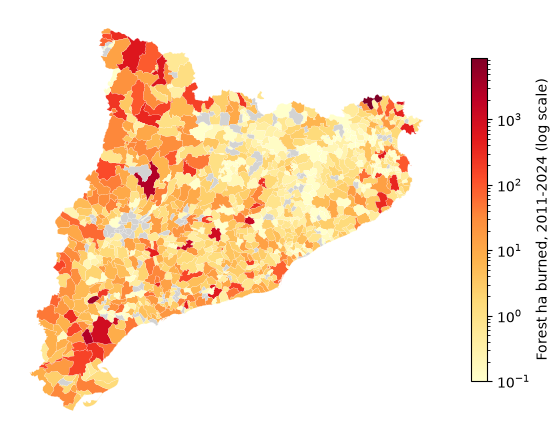

In [29]:
fig, ax = plt.subplots(figsize=(7, 7))

# Draw the map, colouring each municipality by its burned hectares
map_cat.plot(
    column="ha_burned",                   # the column that decides the colour
    cmap="YlOrRd",                        # scale from yellow (little) to dark red (a lot)
    norm=LogNorm(vmin=0.1, vmax=map_cat["ha_burned"].max()),  # log scale: most municipalities burn very little and a few burn a huge amount
    legend=True,                          # add the colour bar
    legend_kwds={"label": "Forest ha burned, 2011-2024 (log scale)", "shrink": 0.6},  # colour bar text and size
    missing_kwds={"color": "lightgrey"},  # municipalities with no data are drawn in light grey
    edgecolor="white",                    # white border between municipalities
    linewidth=0.1,                        # very thin border so it does not hide the colours
    ax=ax,                                # tell it which area to draw on
)

ax.set_axis_off() # we don't need axis
fig.savefig("fires_map.png", dpi=200, bbox_inches="tight")
plt.show()